In [ ]:
%pip install nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')
nltk.download('omw-1.4')
import os
import string
import warnings
warnings.filterwarnings('ignore')
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
print(' All libraries loaded and NLTK resources downloaded successfully')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


 All libraries loaded and NLTK resources downloaded successfully


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
sample_text = 'Hello World! We are learning text preprocessing today!'
print("Original text:", sample_text)                     #lowercasing
text_lower = sample_text.lower()
print("\n1. Lowercasing Output:", text_lower)

Original text: Hello World! We are learning text preprocessing today!

1. Lowercasing Output: hello world! we are learning text preprocessing today!


In [ ]:
tokens = word_tokenize(text_lower)
print("\n2. Tokenization Output:", tokens)   #tokenization


2. Tokenization Output: ['hello', 'world', '!', 'we', 'are', 'learning', 'text', 'preprocessing', 'today', '!']


In [ ]:
tokens_no_punct = [ word for word in tokens if word not in string.punctuation]
print('\n3. punctuation Removed:',tokens_no_punct)             #remove punctuations


3. punctuation Removed: ['hello', 'world', 'we', 'are', 'learning', 'text', 'preprocessing', 'today']


In [ ]:
stop_words = set(stopwords.words('english'))
token_no_stopwords = [word for word in tokens_no_punct if word not in stop_words]
print('\n4. Stopwords Removed:',token_no_stopwords)        #removing stop words


4. Stopwords Removed: ['hello', 'world', 'learning', 'text', 'preprocessing', 'today']


In [ ]:
stemmer = PorterStemmer()
stemmed_tokens = [ stemmer.stem(word) for word in token_no_stopwords]             #stemming (chop krna verb form ko and make a simple word)
print("\n5 Stemmed Tokens:", stemmed_tokens)


5 Stemmed Tokens: ['hello', 'world', 'learn', 'text', 'preprocess', 'today']


In [ ]:
clean_sentence = "".join(stemmed_tokens)
print("\nFinal preprocessed Text:", clean_sentence)


Final preprocessed Text: helloworldlearntextpreprocesstoday


In [ ]:
toy_corpus = [
    "The cat chased the mouse.",
    "The dog chased the cat.",
    "The bird sang in the tree.",
]
print("=== Bag of Words Representation (Counts)===")
count_vect = CountVectorizer()
bow_matrix = count_vect.fit_transform(toy_corpus)
df_bow = pd.DataFrame(bow_matrix.toarray(), columns=count_vect.get_feature_names_out())
display(df_bow)

=== Bag of Words Representation (Counts)===


,bird,cat,chased,dog,in,mouse,sang,the,tree
0,0,1,1,0,0,1,0,2,0
1,0,1,1,1,0,0,0,2,0
2,1,0,0,0,1,0,1,2,1


In [ ]:
print("\n=== TF-IDF Representation(Scaled Weights) ===")
tfidf_vect = TfidfVectorizer()
tfidf_matrix = tfidf_vect.fit_transform(toy_corpus)
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vect.get_feature_names_out())
display(df_tfidf.round(3))


=== TF-IDF Representation(Scaled Weights) ===


,bird,cat,chased,dog,in,mouse,sang,the,tree
0,0.000,0.404,0.404,0.000,0.000,0.531,0.000,0.627,0.000
1,0.000,0.404,0.404,0.531,0.000,0.000,0.000,0.627,0.000
2,0.431,0.000,0.000,0.000,0.431,0.000,0.431,0.509,0.431


In [ ]:
df = pd.read_csv('spam.csv', encoding='latin-1')
df = df[['v1', 'v2']].rename(columns={'v1': 'label', 'v2': 'text'})
print("Successfully loaded the real SMS Spam dataset from local CSV!")

Successfully loaded the real SMS Spam dataset from local CSV!


In [ ]:
df['is_spam'] = df['label'].map({'ham': 0, 'spam': 1})
print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns.\n")
print("Class Distribution (ham vs. spam):")
print(df['label'].value_counts())
print("\nFirst 5 rows:")
display(df.head())

Dataset Shape: 5572 rows and 3 columns.

Class Distribution (ham vs. spam):
label
ham     4825
spam     747
Name: count, dtype: int64

First 5 rows:


,label,text,is_spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [ ]:
def preprocess_text(text):
    text = text.lower()
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in string.punctuation]
    stop_words = set(stopwords.words('english'))
    tokens = [word for word in tokens if word not in stop_words]
    stemmer = PorterStemmer()
    tokens = [stemmer.stem(word) for word in tokens]
    return " ".join(tokens)

In [ ]:
print("cleaning all sms messages in the dataset...(this may take a few seconds)")
df['clean_text']=df['text'].apply(preprocess_text)
print("preprocessing complete")
print("\noriginal:", df['text'].iloc[1])
print("Cleaned:", df['clean_text'].iloc[1])

cleaning all sms messages in the dataset...(this may take a few seconds)
preprocessing complete

original: Ok lar... Joking wif u oni...
Cleaned: ok lar ... joke wif u oni ...


In [ ]:
x_train, x_test, y_test, y_train = train_test_split(
    df['clean_text'], df['is_spam'], test_size=0.20, random_state=42,stratify=df['is_spam']
)
print(f"Train size:{x_train.shape[0]}  Test size:{x_test.shape[0]}\n")

Train size:4457  Test size:1115



In [ ]:
tfidf = TfidfVectorizer(max_features = 2500)
x_train_tfidf = tfidf.fit_transform(x_train)
x_test_tfidf = tfidf.transform(x_test)

In [ ]:
nb_classifier = MultinomialNB()
nb_classifier.fit(x_train_tfidf, y_test)
print(" Naive Bayes model trained successfully!")
y_pred = nb_classifier.predict(x_test_tfidf)
accuracy = accuracy_score(y_train, y_pred)
print(f"Model Test Accuracy: {accuracy*100:.2f}%\n")

 Naive Bayes model trained successfully!
Model Test Accuracy: 97.67%



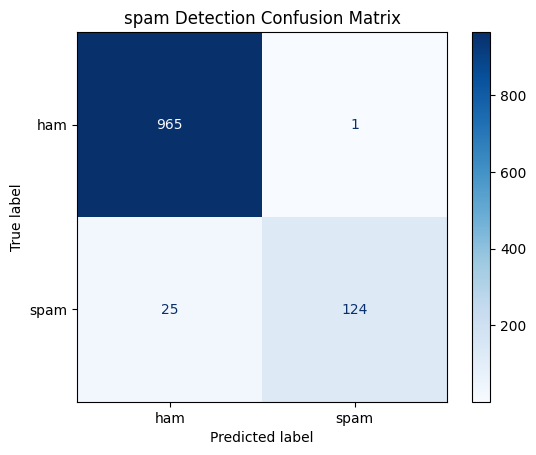

In [ ]:
cm = confusion_matrix(y_train, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['ham','spam'])
disp.plot(cmap='Blues')
plt.grid(False)
plt.title('spam Detection Confusion Matrix')
plt.show()

In [ ]:
print("Classification Report:")
print(classification_report(y_train, y_pred, target_names=['Ham','Spam']))

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.99       966
        Spam       0.99      0.83      0.91       149

    accuracy                           0.98      1115
   macro avg       0.98      0.92      0.95      1115
weighted avg       0.98      0.98      0.98      1115



In [ ]:
custom_texts = [
    "Hey, are we still meeting for coffee at Starbucks today at 3pm?",
    "Congratulations! You have won a free $1000 cash prize. Click here now to claim your reward.",
    "Call me back when you get a chance.",
    "URGENT: Your account password has expired. Click here to reset now!"
]
cleaned_custom = [preprocess_text(msg) for msg in custom_texts]
custom_tfidf = tfidf.transform(cleaned_custom)
custom_predictions = nb_classifier.predict(custom_tfidf)
print("Custom Prediction Output:")
print("-"*80)
for msg, pred in zip(custom_texts, custom_predictions):
  result = "spam" if pred == 1 else "HAM (safe)"
  print(f"Message : {msg}")
  print(f"Flag : {result}")
  print("-"*80)

Custom Prediction Output:
--------------------------------------------------------------------------------
Message : Hey, are we still meeting for coffee at Starbucks today at 3pm?
Flag : HAM (safe)
--------------------------------------------------------------------------------
Message : Congratulations! You have won a free $1000 cash prize. Click here now to claim your reward.
Flag : spam
--------------------------------------------------------------------------------
Message : Call me back when you get a chance.
Flag : HAM (safe)
--------------------------------------------------------------------------------
Message : URGENT: Your account password has expired. Click here to reset now!
Flag : spam
--------------------------------------------------------------------------------


In [ ]:
def preprocess_with_lemmatizer(text):
  text = text.lower()
  tokens = word_tokenize(text)
  tokens = [word for word in tokens if word not in string.punctuation]
  stop_words = set(stopwords.words('english'))
  tokens = [word for word in tokens if word not in stop_words]
  lemmatizer = WordNetLemmatizer()
  tokens = [lemmatizer.lemmatize(word) for word in tokens]
  return " ".join(tokens)

print("Preprocessing dataset using WordNet Lemmatizer...")
df['clean_text_lem'] = df['text'].apply(preprocess_with_lemmatizer)

x_train_lem, x_test_lem, y_train_lem, y_test_lem = train_test_split(
    df['clean_text_lem'], df['is_spam'], test_size=0.2, random_state=42, stratify=df['is_spam']
)

tfidf_lem = TfidfVectorizer(max_features=2500, )
x_train_lem_tfidf = tfidf_lem.fit_transform(x_train_lem)
x_test_lem_tfidf = tfidf_lem.transform(x_test_lem)

nb_lem = MultinomialNB().fit(x_train_lem_tfidf, y_train_lem)
acc_lem = accuracy_score(y_test_lem, nb_lem.predict(x_test_lem_tfidf))
print(f"\nStemming Pipelines Accuracy: {accuracy*100:.2f}%")
print(f"Lemmatization Pipelines Accuracy: {acc_lem*100:.2f}%")

Preprocessing dataset using WordNet Lemmatizer...

Stemming Pipelines Accuracy: 97.67%
Lemmatization Pipelines Accuracy: 97.94%
